# 문장의 어느 부분을 찾았고, 왜 -3점이 되었을까?

A4-1은 같은 단어의 빈도로 문서를 비교했다. A4-2는 **패턴의 위치와 규칙의 적용 범위**로
개체·감성을 판단한다. 먼저 합성 문의 하나에서 후보·그룹·위치·정규화·겹침을 추적하고,
짧은 감성 문장 하나의 점수를 직접 계산한다. 그 뒤 기존 모듈로 평가와 보너스를 실행한다.
기본은 정규식 추출과 사전 기반 감성이다. 마스킹·속성·통계 분류 비교는 뒤에서 연결한다.

A4-2에서 `uv sync --group dev` 후 `.venv`를 커널로 선택해 위에서 아래로 실행한다.
`uv run --group dev python tools/build_learning_notebook.py --execute`로 새 커널 실행·재생성한다.
NSMC/KNU 캐시가 없으면 다운로드한다. 전체 평가·학습 곡선은 수 분 걸릴 수 있다.
기존 outputs는 읽어서 대조하며 덮어쓰지 않는다. 원문 리뷰는 짧은 실패 예시 하나만 보여 준다.

[HTML](../study/a4-2.html)은 패턴·규칙 스위치를 조작하는 용도,
이 노트북은 실제 Python 배열·자료구조·계산·평가 경계를 확인하는 용도다.

In [1]:
from pathlib import Path
import sys
import json
import platform
import math
from dataclasses import asdict, replace
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root/'src/sentiment.py').is_file(), 'A4-2 또는 notebooks에서 실행하세요.'
sys.path.insert(0, str(root))
from src import patterns, normalize, extract, sentiment, eval_extraction, eval_sentiment, metrics, aspect, bonus_tfidf
from src.data import load_splits, load_knu
from main import hide_entities
thread_limit = threadpool_limits(limits=2)
print('Python', platform.python_version(), 'NumPy', np.__version__, 'sklearn', sklearn.__version__)

def table(headers, rows):
    lines = ['| ' + ' | '.join(map(str, headers)) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(str(value).replace('|', '/') for value in row) + ' |')
    display(Markdown('\n'.join(lines)))

Python 3.12.13 NumPy 2.5.4 sklearn 1.9.1


## 1. 정규식은 후보를 찾고 정규화는 유효성을 판단한다

합성 문의에서 각 유형의 `finditer`를 직접 돌린다. `group(0)`은 매칭 전체,
`groupdict()`는 이름 붙인 부분이다. `start:end`에서 end는 제외된다.
아래의 2023년 2월 29일도 글자 모양은 날짜지만 실제 날짜가 아니므로 정규화에서 버린다.
이메일·금액은 변환된 값과 원문 문자열을 함께 보관한다.

In [2]:
inquiry = '문의: demo@example.com, 예약 2024년 3월 15일, 변경 2023년 2월 29일, 참가비 5만원. 정말 맛있지 않았어요'
raw_candidates = []
for kind in patterns.CORE_TYPES:
    for match in patterns.COMPILED[kind].finditer(inquiry):
        raw = match.group(0)
        start, end = match.span()
        groups = match.groupdict()
        converted = normalize.normalize(kind, groups, raw)
        assert inquiry[start:end] == raw
        raw_candidates.append((kind, raw, start, end, groups, converted))
for kind, raw, start, end, groups, converted in raw_candidates:
    print(kind, repr(raw), f'[{start}:{end}]', '그룹:', groups, '→', converted)
print('정규화가 거절한 후보:', [raw for _, raw, _, _, _, value in raw_candidates if value is None])

email 'demo@example.com' [4:20] 그룹: {'local': 'demo', 'domain': 'example.com'} → ('demo@example.com', {})
date '2024년 3월 15일' [25:37] 그룹: {'y': '2024', 'm': '3', 'd': '15', 'y2': None, 'sep': None, 'm2': None, 'd2': None, 'mon': None, 'd3': None, 'y3': None} → ('2024-03-15', {})
date '2023년 2월 29일' [42:54] 그룹: {'y': '2023', 'm': '2', 'd': '29', 'y2': None, 'sep': None, 'm2': None, 'd2': None, 'mon': None, 'd3': None, 'y3': None} → None
money '5만원' [60:63] 그룹: {'krw': '5만', 'won_sym': None, 'usd': None, 'usd2': None} → (50000, {'currency': 'KRW'})
정규화가 거절한 후보: ['2023년 2월 29일']


## 2. 유효한 Entity를 만들고 겹침을 해결하기

Entity는 유형·원문·원래 위치·정규화 값·부가정보를 묶는 dataclass다.
후보끼리 겹치면 긴 범위를 먼저, 같은 길이면 PRIORITY 순서로 남긴다.
‘전화로도 보이는 카드번호’ 같은 충돌을 처리하는 결정 규칙이며 의미 이해는 아니다.
실제 문의의 후보를 확인한 뒤, 규칙만 분리해 보는 합성 겹침 예를 만든다.

In [3]:
validated = extract.candidates(inquiry)
entities = extract.resolve_overlaps(validated)
assert entities == extract.extract(inquiry)
table(['유형', '원문', 'start', 'end', '값', '부가정보'],
      [[e.type, e.text, e.start, e.end, e.value, e.info] for e in entities])
print('첫 개체의 사전 표현:', asdict(entities[0]))
assert all(inquiry[e.start:e.end] == e.text for e in entities)
assert all(a.end <= b.start for a, b in zip(entities, entities[1:]))
fake = [extract.Entity('phone', '짧은 후보', 0, 5, 'toy'),
        extract.Entity('card', '더 긴 후보', 0, 9, 'toy')]
print('겹침 규칙 합성 예:', [e.type for e in extract.resolve_overlaps(fake)])
fake_tie = [extract.Entity('phone', '같은 길이', 0, 9, 'toy'),
            extract.Entity('rrn', '같은 길이', 0, 9, 'toy')]
print('길이 동점 우선순위:', patterns.PRIORITY, '→', [e.type for e in extract.resolve_overlaps(fake_tie)])

| 유형 | 원문 | start | end | 값 | 부가정보 |
| --- | --- | --- | --- | --- | --- |
| email | demo@example.com | 4 | 20 | demo@example.com | {} |
| date | 2024년 3월 15일 | 25 | 37 | 2024-03-15 | {} |
| money | 5만원 | 60 | 63 | 50000 | {'currency': 'KRW'} |

첫 개체의 사전 표현: {'type': 'email', 'text': 'demo@example.com', 'start': 4, 'end': 20, 'value': 'demo@example.com', 'info': {}}
겹침 규칙 합성 예: ['card']
길이 동점 우선순위: ('rrn', 'card', 'email', 'url', 'phone', 'date', 'money', 'address') → ['rrn']


## 3. 5만원이 50000이 되는 계산과 개체 가림

첫 금액은 ‘5’ 다음 ‘만’을 만나 `5 × 10000`이 된다. 복잡한 한글 수사는 기존 파서를 재사용한다.
원화는 원 단위 정수, 달러는 센트 단위 정수다. 값만 보고 화폐 단위를 추정하지 않는다.
CLI는 감성 분석 전에 개체 구간을 □ 하나로 바꿔 이메일의 마침표·날짜의 숫자가 감성 규칙에
들어가는 것을 막는다. 길이가 줄어들므로 **감성 분석 좌표는 원래 문의의 좌표가 아니다.**

In [4]:
amount_number = 5
large_unit = 10000
amount_won = amount_number * large_unit
assert amount_won == normalize.parse_korean_amount('5만') == 50000
plain = hide_entities(inquiry, entities)
print('원문 길이:', len(inquiry), '→ 감성 입력 길이:', len(plain))
print('감성 입력:', plain)
print('부가정보에 표시한 단위:', [(e.value, e.info) for e in entities if e.type == 'money'])
print('실제 달력 검증:', normalize.iso_date(2023, 2, 29), normalize.iso_date(2024, 2, 29))

원문 길이: 76 → 감성 입력 길이: 48
감성 입력: 문의: □, 예약 □, 변경 2023년 2월 29일, 참가비 □. 정말 맛있지 않았어요
부가정보에 표시한 단위: [(50000, {'currency': 'KRW'})]
실제 달력 검증: None 2024-02-29


## 4. 토큰·설명용 조각·사전 Hit는 다른 목록이다

‘이 식당은 정말 맛있지 않았어요’를 첫 감성 사례로 쓴다.
`normalize_text`는 NFC·영문 소문자·공백을 정리하고, tokenize는 글자 종류와 어절 번호를 붙인다.
Matcher는 사전에 있는 부분을 찾아 Hit를 만든다. 출력용 pieces는 그 Hit를 이용해 어미·조사를
나눈 설명용 조각이다. 셋을 같은 형태소 분석 결과라고 부르지 않는다.
위치는 정규화된 문자열의 Python 글자 인덱스다.

In [5]:
raw_sentence = '이 식당은 정말 맛있지 않았어요'
text = sentiment.normalize_text(raw_sentence)
tokens = sentiment.tokenize(text)
analyzer = sentiment.SentimentAnalyzer()
hits = analyzer.matcher.find(text)
clause_ids, last_strong = sentiment.clause_map(text, tokens)
table(['토큰', '종류', 'start', 'end', '어절', '절'],
      [[t.text, t.kind, t.start, t.end, t.eojeol, clause_ids[t.start]] for t in tokens])
table(['Hit 표면형', '종류', '표제어', '점수/배율', 'start', 'end', 'flags'],
      [[h.surface, h.kind, h.entry.term, h.entry.score, h.start, h.end, sorted(h.entry.flags)] for h in hits])
assert all(text[h.start:h.end] == h.surface for h in hits)
print('last_strong:', last_strong)
print('사전 설정은 유지하고 문장마다 Hit와 계산 결과를 새로 만든다.')

| 토큰 | 종류 | start | end | 어절 | 절 |
| --- | --- | --- | --- | --- | --- |
| 이 | hangul | 0 | 1 | 0 | 0 |
| 식당은 | hangul | 2 | 5 | 1 | 0 |
| 정말 | hangul | 6 | 8 | 2 | 0 |
| 맛있지 | hangul | 9 | 12 | 3 | 0 |
| 않았어요 | hangul | 13 | 17 | 4 | 0 |

| Hit 표면형 | 종류 | 표제어 | 점수/배율 | start | end | flags |
| --- | --- | --- | --- | --- | --- | --- |
| 정말 | INT | 정말 | 1.5 | 6 | 8 | [] |
| 맛있 | SENTI | 맛있 | 2.0 | 9 | 11 | [] |
| 않 | NEG_POST | 않 | -1.0 | 13 | 14 | [] |

last_strong: None
사전 설정은 유지하고 문장마다 Hit와 계산 결과를 새로 만든다.


## 5. 첫 -3점을 직접 계산하기

이 사례의 ‘정말’은 감성어 앞 같은 절·2어절 이내, ‘않’은 감성어 뒤 같은 절·3어절 이내다.
중간에 다른 감성어도 없다. 이 조건을 확인한 뒤 `+2 × (-1) × 1.5 × 1 = -3`을 계산한다.
마지막 1은 대조 배율이다. 기본 사전은 고정 규칙이며 이 문장으로 모델을 학습하지 않는다.

In [6]:
feeling = next(h for h in hits if h.kind == 'SENTI')
modifier = next(h for h in hits if h.kind == 'INT')
negator = next(h for h in hits if h.kind == 'NEG_POST')
def eojeol_at(position):
    return text[:position].count(' ')
assert clause_ids[modifier.start] == clause_ids[feeling.start] == clause_ids[negator.start]
print('강조어 거리:', eojeol_at(feeling.start) - eojeol_at(modifier.start))
print('뒤 부정어 거리:', eojeol_at(negator.start) - eojeol_at(feeling.end - 1))
base_score = feeling.entry.score
multiplier = modifier.entry.score
sign = -1
contrast = 1
hand_score = base_score * sign * multiplier * contrast
result = analyzer.analyze(raw_sentence, sentiment.REQUIRED_CONFIG)
assert hand_score == result.score == -3
print('직접 계산:', base_score, '×', sign, '×', multiplier, '×', contrast, '=', hand_score)
print('pieces:', result.pieces)
print('Scored 하나:', asdict(result.items[0]))
print(sentiment.explain(result))

강조어 거리:

 1
뒤 부정어 거리: 1
직접 계산: 2.0 × -1 × 1.5 × 1 = -3.0
pieces: [('이', 'rest'), ('식당', 'rest'), ('은', 'josa'), ('정말', 'int'), ('맛있', 'senti'), ('지', 'rest'), ('않았어요', 'neg')]
Scored 하나: {'surface': '맛있', 'term': '맛있', 'base': 2.0, 'start': 9, 'modifiers': [('정말', 1.5)], 'negators': ['않'], 'contrast': 1.0, 'value': -3.0, 'kind': 'SENTI', 'negation_factor': -1}
=== 감성 분석 과정 ===
문장: "이 식당은 정말 맛있지 않았어요"

1. 토큰화: [이, 식당, 은, 정말, 맛있, 지, 않았어요]
2. 감성 단어 탐지: 맛있(+2)
3. 부정어 탐지: '않' → 실제 배율 맛있: ×-1
4. 강조어 탐지: '정말' → 강도 ×1.5

계산: (+2) × (-1) × 1.5 = -3
최종 판정: 부정


## 6. 탐지한 부정어 수와 실제 반전은 구별한다

이중부정을 켜면 두 번 반전해 원래 극성으로 돌아온다. 끄면 한 번만 반전한다.
`negators`는 탐지 목록, `negation_factor`는 설정을 적용한 실제 배율이다.
일반 사례의 값은 기본 점수 × 강조/약화 배율들의 곱 × 실제 부정 배율 × 대조 배율이다.
확장 규칙에서는 고립 부정어·평점 기여를 따로 더한다.

In [7]:
double_text = '재미있지 않을 수 없다'
for enabled in [False, True]:
    cfg = replace(sentiment.REQUIRED_CONFIG, double_negation=enabled)
    r = analyzer.analyze(double_text, cfg)
    print('이중부정:', enabled, '탐지:', r.items[0].negators,
          '실제 배율:', r.items[0].negation_factor, '점수:', r.score)
    print(sentiment.explain(r).split('계산: ')[1].splitlines()[0])
examples = ['정말 맛있지 않았어요', '좋지만 별로', '10점 만점에 1점', '이건 아니다',
            '좋다 나쁘다', '문의만 남깁니다', '좋지 않고 재미없다', '안 좋다', 'ㅋㅋㅋㅋ', '']
rows = []
for sentence in examples:
    r = analyzer.analyze(sentence, sentiment.FINAL_CONFIG)
    values = []
    for item in r.items:
        factor = 1
        for _, value in item.modifiers:
            factor *= value
        reconstructed = item.base * factor * item.negation_factor * item.contrast
        assert math.isclose(reconstructed, item.value)
        values.append(item.value)
    extra = sum(o['value'] for o in r.orphans) + (r.rating['value'] if r.rating else 0)
    assert round(sum(values) + extra, 6) == r.score
    rows.append([sentence or '(빈 문장)', values, extra, r.score, r.label, r.decided_by_tie])
table(['문장', '감성어 기여', '확장 기여', '합', '판정 0/1', '0점 기본값'], rows)

이중부정: False 탐지: ['않', '없'] 실제 배율: -1 점수: -2.0
(+2) × (-1) = -2
이중부정: True 탐지: ['않', '없'] 실제 배율: 1 점수: 2.0
(+2) × (+1) = 2


| 문장 | 감성어 기여 | 확장 기여 | 합 | 판정 0/1 | 0점 기본값 |
| --- | --- | --- | --- | --- | --- |
| 정말 맛있지 않았어요 | [-3.0] | 0 | -3.0 | 0 | False |
| 좋지만 별로 | [1.0, -3.0] | 0 | -2.0 | 0 | False |
| 10점 만점에 1점 | [] | -2.0 | -2.0 | 0 | False |
| 이건 아니다 | [] | -1.0 | -1.0 | 0 | False |
| 좋다 나쁘다 | [2.0, -2.0] | 0 | 0.0 | 0 | True |
| 문의만 남깁니다 | [] | 0 | 0 | 0 | True |
| 좋지 않고 재미없다 | [-2.0, -2.0] | 0 | -4.0 | 0 | False |
| 안 좋다 | [-2.0] | 0 | -2.0 | 0 | False |
| ㅋㅋㅋㅋ | [0.5] | 0 | 0.5 | 1 | False |
| (빈 문장) | [] | 0 | 0 | 0 | True |

0점은 ‘단서가 없음’과 ‘기여의 상쇄’를 모두 포함한다. 기본 tie_label=0은 부정으로 처리하는
결정 규칙이며 중립 확률이 아니다. `좋다 나쁘다`는 감성 기여가 있어도 합이 0이 된다.
감성 점수는 학습된 확률이 아니고, 규칙을 더 켜도 모든 문장에서 개선되지는 않는다.

## 7. 첫 추출 평가의 분모를 직접 세기

현재 평가는 `(유형, 원문 문자열)`의 다중집합 비교다. 위치 자체는 비교하지 않는다.
같은 문자열의 중복 개수는 세지만 어느 위치를 찾았는지는 이 지표로 검증할 수 없다.
정규화 정확도는 TP 중 값까지 맞은 비율이다. 탐지하지 못한 개체는 이 분모에 들어가지 않는다.

In [8]:
predicted = [('date', '2024년 3월 15일'), ('money', '5만원')]
gold = [('date', '2024년 3월 15일'), ('email', 'demo@example.com')]
matched, false_positive, missed = eval_extraction._match(predicted, gold)
tp, fp, fn = len(matched), len(false_positive), len(missed)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print('TP:', matched, 'FP:', false_positive, 'FN:', missed)
print('P/R/F1:', precision, recall, f1)
assert metrics.prf(tp, fp, fn)['f1'] == f1 == 0.5
print('값까지 맞은 TP가 1건이면 정규화 정확도는 1/1이지만 검출 재현율은 1/2이다.')
extraction_eval = eval_extraction.evaluate_extraction()
old_extraction = json.loads((root/'outputs/extraction_eval.json').read_text(encoding='utf-8'))
assert extraction_eval['micro'] == old_extraction['micro']
table(['유형', 'TP', 'FP', 'FN', 'P', 'R', 'F1', '정규화 정확도'],
      [[kind] + [round(row[key], 6) if isinstance(row[key], float) else row[key]
                 for key in ['tp', 'fp', 'fn', 'precision', 'recall', 'f1', 'normalization_accuracy']]
       for kind, row in extraction_eval['per_type'].items()])
print('80문장 micro:', extraction_eval['micro'])

TP: [('date', '2024년 3월 15일')] FP: [('money', '5만원')] FN: [('email', 'demo@example.com')]
P/R/F1: 0.5 0.5 0.5
값까지 맞은 TP가 1건이면 정규화 정확도는 1/1이지만 검출 재현율은 1/2이다.


| 유형 | TP | FP | FN | P | R | F1 | 정규화 정확도 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| email | 14 | 1 | 2 | 0.933333 | 0.875 | 0.903226 | 1.0 |
| phone | 14 | 0 | 2 | 1.0 | 0.875 | 0.933333 | 1.0 |
| date | 19 | 0 | 3 | 1.0 | 0.863636 | 0.926829 | 1.0 |
| money | 17 | 3 | 2 | 0.85 | 0.894737 | 0.871795 | 1.0 |
| url | 13 | 1 | 2 | 0.928571 | 0.866667 | 0.896552 | 1.0 |

80문장 micro: {'tp': 77, 'fp': 5, 'fn': 11, 'precision': 0.9390243902439024, 'recall': 0.875, 'f1': 0.9058823529411764}


## 8. 실제 감성 평가: dev·test·pool의 역할

dev는 사전·규칙 선택, test는 고정 규칙 평가, pool은 통계 분류기의 학습 표본용이다.
원본 train에서 dev를 뺀 pool과 원본 test에서 뽑은 test가 있다. seed=42로 고정한다.
지금은 기존 규칙을 고정한 재현 평가다. 이미 test 결과를 본 뒤 새 규칙을 고르면
같은 test를 미지의 최종 평가라고 부를 수 없다. 아래 결과로 규칙을 튜닝하지 않는다.

In [9]:
splits = load_splits()
print('분할 수:', {name: len(rows) for name, rows in splits.items()})
ids = {name: {row['id'] for row in rows} for name, rows in splits.items()}
for name, rows in splits.items():
    assert len(ids[name]) == len(rows)
assert ids['dev'].isdisjoint(ids['pool'])
assert ids['dev'].isdisjoint(ids['test'])
assert ids['pool'].isdisjoint(ids['test'])
print('분할 사이 ID 교집합: 0. 동일 본문 중복 여부와는 다른 검사다.')
evaluation = eval_sentiment.run(splits, load_knu())
saved = json.loads((root/'outputs/sentiment_eval.json').read_text(encoding='utf-8'))
for name in ['dev', 'test']:
    for current, previous in zip(evaluation[name]['ablation'], saved[name]['ablation']):
        assert current['step'] == previous['step']
        for key in ['accuracy', 'macro_f1', 'ties']:
            assert current[key] == previous[key]
table(['단계', 'dev 정확도', 'test 정확도', 'test macro F1', 'test 0점'],
      [[d['step'], d['accuracy'], t['accuracy'], round(t['macro_f1'], 6), t['ties']]
       for d, t in zip(evaluation['dev']['ablation'], evaluation['test']['ablation'])])
print('Test 최종:', evaluation['test']['final_report'])
print('Test 최종 bootstrap 구간:', evaluation['test']['significance']['ci95'][sentiment.ABLATION_STEPS[-1][0]])
print('부정어 적용 부분집합:', {k: v for k, v in evaluation['test']['negation_subset'].items() if k != 'examples'})

분할 수: {'dev': 1000, 'test': 1000, 'pool': 148995}
분할 사이 ID 교집합: 0. 동일 본문 중복 여부와는 다른 검사다.


| 단계 | dev 정확도 | test 정확도 | test macro F1 | test 0점 |
| --- | --- | --- | --- | --- |
| A 사전 합산만 | 0.759 | 0.719 | 0.713784 | 404 |
| B A + 강조어 | 0.76 | 0.721 | 0.716279 | 397 |
| C A + 부정어(한 번만 반전) | 0.784 | 0.734 | 0.728526 | 403 |
| D A + 부정어 + 강조어 | 0.784 | 0.734 | 0.728836 | 397 |
| E D + 이중부정 (필수 범위) | 0.784 | 0.733 | 0.727893 | 397 |
| F E + 이모티콘 | 0.798 | 0.752 | 0.749595 | 349 |
| G F + 대조 접속 | 0.801 | 0.756 | 0.753535 | 347 |
| H G + 고립 부정어 | 0.8 | 0.757 | 0.753389 | 278 |
| I H + 평점 언급 | 0.806 | 0.762 | 0.758977 | 264 |

Test 최종: {'n': 1000, 'accuracy': 0.762, 'negative': {'tp': 437, 'fp': 175, 'fn': 63, 'precision': 0.7140522875816994, 'recall': 0.874, 'f1': 0.7859712230215827}, 'positive': {'tp': 325, 'fp': 63, 'fn': 175, 'precision': 0.8376288659793815, 'recall': 0.65, 'f1': 0.731981981981982}, 'macro_f1': 0.7589766025017823, 'confusion': [[437, 63], [175, 325]]}
Test 최종 bootstrap 구간: {'accuracy': (0.734, 0.788), 'macro_f1': (0.7320458050001264, 0.7843397987103315)}
부정어 적용 부분집합: {'n': 72, 'acc_A': 0.5, 'acc_E': 0.6805555555555556, 'mcnemar_A_vs_E': {'a_only': 14, 'b_only': 27, 'p_value': 0.05958388801809633}}


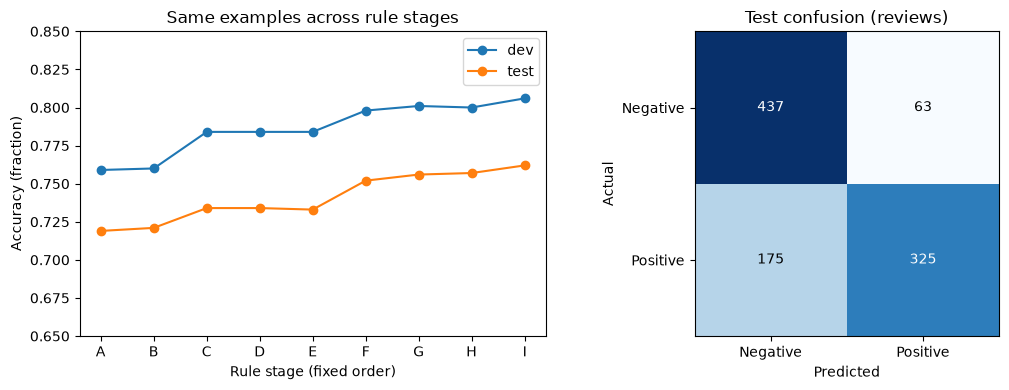

고정된 Test 순서의 첫 오분류: 9985453 실제: 1 예측: 0 점수: 0
리뷰 일부: 에바그린때문에 살았다. 이영화
계산 기여: []
단어 기여는 규칙의 계산 근거다. 작성자의 의도나 오분류의 인과적 원인을 증명하지 않는다.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ['dev', 'test']:
    axes[0].plot(list('ABCDEFGHI'), [r['accuracy'] for r in evaluation[name]['ablation']], marker='o', label=name)
axes[0].set(xlabel='Rule stage (fixed order)', ylabel='Accuracy (fraction)', title='Same examples across rule stages', ylim=(0.65, 0.85))
axes[0].legend()
cm = np.array(evaluation['test']['final_report']['confusion'])
axes[1].imshow(cm, cmap='Blues')
axes[1].set_xticks([0, 1], ['Negative', 'Positive'])
axes[1].set_yticks([0, 1], ['Negative', 'Positive'])
axes[1].set(xlabel='Predicted', ylabel='Actual', title='Test confusion (reviews)')
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm[i, j]), ha='center', va='center',
                     color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout()
plt.show()
plt.close(fig)
error = evaluation['test_errors'][0]
print('고정된 Test 순서의 첫 오분류:', error['id'], '실제:', error['label'], '예측:', error['pred'], '점수:', error['score'])
print('리뷰 일부:', error['text'][:140])
print('계산 기여:', error['evidence'])
print('단어 기여는 규칙의 계산 근거다. 작성자의 의도나 오분류의 인과적 원인을 증명하지 않는다.')

## 9. 보너스: 마스킹과 속성별 감성

감성 입력용 □ 치환과 개인정보 표시용 마스킹은 다르다. 후자는 일부 자리·도메인을 남긴다.
패턴이 놓치는 표기는 마스킹도 놓친다. CLI/JSON은 원문·검출 개체도 포함하므로
`--mask`가 출력 전체를 비식별화하는 옵션이라고 생각하면 안 된다.
속성 분석은 같은 문장 안의 맛/가격을 서로 다른 극성으로 연결하는 별도 과제다.

In [11]:
contact = '연락 demo@example.com, 010-1234-5678'
masked, masked_entities = extract.mask(contact)
print('합성 연락처:', contact, '→', masked)
mask_eval = eval_extraction.evaluate_masking()
old_mask = json.loads((root/'outputs/masking_eval.json').read_text(encoding='utf-8'))
assert mask_eval['leak_rate'] == old_mask['leak_rate']
print('합성 평가 개인정보 수 / 남은 원문 수:', mask_eval['n_gold'], len(mask_eval['leaks']))
aa = aspect.AspectAnalyzer()
ar = aa.analyze('음식은 맛있는데 가격이 비싸요')
print(aspect.format_report(ar))
print('절의 연결 기록:', ar.clauses)
aspect_eval = aspect.evaluate()
old_aspect = json.loads((root/'outputs/aspect_eval.json').read_text(encoding='utf-8'))
assert aspect_eval['pair'] == old_aspect['preceding']['pair']
print('속성 쌍 F1:', aspect_eval['pair']['f1'], '문장 전체 극성 기준선:', aspect_eval['sentence_baseline']['f1'])

합성 연락처: 연락 demo@example.com, 010-1234-5678 → 연락 de***@example.com, 010-****-5678
합성 평가 개인정보 수 / 남은 원문 수: 20 3
=== 속성 기반 감성 분석 ===
문장: "음식은 맛있는데 가격이 비싸요"

- 절 "음식은 맛있는데" 속성 ['맛'] ← 맛있→맛
- 절 "가격이 비싸요" 속성 ['가격'] ← 비싸→가격

결과: 맛(긍정, +2) ← 맛있(+2)
결과: 가격(부정, -2) ← 비싸(-2)
절의 연결 기록: [{'text': '음식은 맛있는데', 'aspects': ['맛'], 'assigned': [('맛있', '맛')]}, {'text': '가격이 비싸요', 'aspects': ['가격'], 'assigned': [('비싸', '가격')]}]
속성 쌍 F1: 0.920863309352518 문장 전체 극성 기준선: 0.6376811594202899


## 10. A4-1에서 이어지는 통계 분류 비교

A4-1의 영어 단어 빈도 검색과 달리, 여기서는 한국어 char_wb 1~3-gram을 특성으로 쓴다.
‘맛있다’를 글자 조각으로 표현하므로 사전의 어간 규칙과도 다르다.
첫 학습 표본에서만 어휘·IDF를 fit, 같은 test에는 transform한다.
y는 0/1 정답, X는 리뷰×글자 조각이다. test의 정답은 fit에 주지 않는다.
혼합형은 TF-IDF 옆에 `tanh(규칙점수/3)`과 `점수0 표시` 두 열을 붙인다.

In [12]:
import random
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack
train = bonus_tfidf.balanced_sample(splits['pool'], 10, random.Random(10000))
train_texts = [row['text'] for row in train]
test_texts = [row['text'] for row in splits['test']]
y_train = np.array([row['label'] for row in train])
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(1, 3), sublinear_tf=True)
X_train = vec.fit_transform(train_texts)
frozen_terms = vec.get_feature_names_out().copy()
frozen_idf = vec.idf_.copy()
X_test = vec.transform(test_texts)
np.testing.assert_array_equal(frozen_terms, vec.get_feature_names_out())
np.testing.assert_array_equal(frozen_idf, vec.idf_)
model = LogisticRegression(C=1., solver='liblinear', max_iter=1000).fit(X_train, y_train)
predicted = model.predict(X_test)
reference_predicted, reference_dim = bonus_tfidf.fit_predict(train, test_texts)
np.testing.assert_array_equal(predicted, reference_predicted)
print('X_train / y_train / X_test:', X_train.shape, y_train.shape, X_test.shape)
print('어휘 앞 12개:', frozen_terms[:12].tolist())
rules_train = bonus_tfidf.rule_features(analyzer, train_texts)
print('첫 리뷰 규칙 특성 2개:', rules_train[0].toarray()[0])
print('혼합 X_train:', hstack([X_train, rules_train]).shape)
print('작은 10건/단일 seed는 한 실험이다. 다음은 표본 변동까지 본 전체 학습 곡선이다.')
curve = bonus_tfidf.run(splits, log=lambda message: None)
old_curve = json.loads((root/'outputs/rule_vs_tfidf.json').read_text(encoding='utf-8'))
assert [(r['model'], r['n'], r['seeds']) for r in curve['curve']] == [
    (r['model'], r['n'], r['seeds']) for r in old_curve['curve']]
print('기존 저장값 대비 평균 정확도의 최대 차이:',
      max(abs(a['acc_mean'] - b['acc_mean']) for a, b in zip(curve['curve'], old_curve['curve'])))
print('고정 규칙을 처음 넘은 TF-IDF 학습 크기:', curve['crossover_n'])
table(['모델', '학습 n', 'seed 수', '정확도 평균', '표준편차', '범위'],
      [[r['model'], r['n'], r['seeds'], round(r['acc_mean'], 4), round(r['acc_std'], 4),
        (round(r['acc_min'], 4), round(r['acc_max'], 4))] for r in curve['curve']])

X_train / y_train / X_test: (10, 538) (10,) (1000, 538)
어휘 앞 12개: [' ', " '", " '조", " '케", ' 개', ' 개유', ' 거', ' 거기', ' 골', ' 골탕', ' 괜', ' 괜찮']
첫 리뷰 규칙 특성 2개: [0.32151274 0.        ]
혼합 X_train: (10, 540)
작은 10건/단일 seed는 한 실험이다. 다음은 표본 변동까지 본 전체 학습 곡선이다.


기존 저장값 대비 평균 정확도의 최대 차이: 0.0
고정 규칙을 처음 넘은 TF-IDF 학습 크기: 3000


| 모델 | 학습 n | seed 수 | 정확도 평균 | 표준편차 | 범위 |
| --- | --- | --- | --- | --- | --- |
| TF-IDF | 10 | 10 | 0.5412 | 0.0273 | (0.483, 0.572) |
| TF-IDF+규칙 점수 | 10 | 10 | 0.7472 | 0.0163 | (0.709, 0.762) |
| TF-IDF | 30 | 10 | 0.5912 | 0.026 | (0.552, 0.639) |
| TF-IDF+규칙 점수 | 30 | 10 | 0.754 | 0.0121 | (0.734, 0.77) |
| TF-IDF | 100 | 10 | 0.6404 | 0.0147 | (0.623, 0.668) |
| TF-IDF+규칙 점수 | 100 | 10 | 0.7595 | 0.01 | (0.74, 0.779) |
| TF-IDF | 300 | 10 | 0.6913 | 0.0109 | (0.67, 0.708) |
| TF-IDF+규칙 점수 | 300 | 10 | 0.7681 | 0.006 | (0.762, 0.781) |
| TF-IDF | 1000 | 10 | 0.7398 | 0.0089 | (0.727, 0.761) |
| TF-IDF+규칙 점수 | 1000 | 10 | 0.7813 | 0.0058 | (0.773, 0.79) |
| TF-IDF | 3000 | 3 | 0.775 | 0.0091 | (0.763, 0.785) |
| TF-IDF+규칙 점수 | 3000 | 3 | 0.799 | 0.0051 | (0.792, 0.804) |
| TF-IDF | 10000 | 3 | 0.8047 | 0.0026 | (0.801, 0.807) |
| TF-IDF+규칙 점수 | 10000 | 3 | 0.8127 | 0.004 | (0.807, 0.816) |

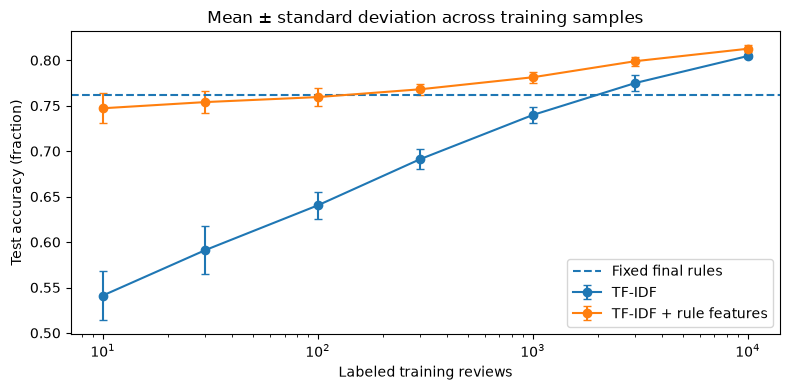

n<=1000은 seed 10개, 그보다 크면 3개다. 오차 막대는 신뢰구간이 아니라 seed 간 표준편차다.
규칙은 학습 표본 n=0이지만, 사전·규칙을 정할 때 사람이 dev 1000건을 읽은 비용이 있다.
같은 test를 반복 비교한 결과다. 보지 않은 새 도메인의 성능을 보장하지 않는다.


In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = ['TF-IDF', 'TF-IDF+규칙 점수']
for label, shown in zip(labels, ['TF-IDF', 'TF-IDF + rule features']):
    rows = [r for r in curve['curve'] if r['model'] == label]
    ax.errorbar([r['n'] for r in rows], [r['acc_mean'] for r in rows],
                yerr=[r['acc_std'] for r in rows], marker='o', capsize=3, label=shown)
ax.axhline(evaluation['test']['final_report']['accuracy'], linestyle='--', label='Fixed final rules')
ax.set(xscale='log', xlabel='Labeled training reviews', ylabel='Test accuracy (fraction)',
       title='Mean ± standard deviation across training samples')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)
print('n<=1000은 seed 10개, 그보다 크면 3개다. 오차 막대는 신뢰구간이 아니라 seed 간 표준편차다.')
print('규칙은 학습 표본 n=0이지만, 사전·규칙을 정할 때 사람이 dev 1000건을 읽은 비용이 있다.')
print('같은 test를 반복 비교한 결과다. 보지 않은 새 도메인의 성능을 보장하지 않는다.')

## 친구에게 시연하는 순서와 확인 질문

1. 합성 문의에서 올바른 날짜·존재하지 않는 날짜를 비교한다. 정규식 후보와 유효 개체가 다른 이유를 말한다.
2. ‘정말 맛있지 않았어요’의 +2, ×1.5, ×(-1)을 보여 준다. 토큰과 사전 Hit를 구별한다.
3. ‘재미있지 않을 수 없다’에서 이중부정 스위치를 바꾸고, 탐지 수와 실제 반전 배율을 비교한다.
4. ‘좋다 나쁘다’와 ‘문의만 남깁니다’가 모두 0점이어도 내부 기여가 다른 것을 보인다.
5. ‘음식은 맛있는데 가격이 비싸요’의 속성별 결과와 마스킹의 검출 한계를 설명한다.

```powershell
uv run python main.py --text "이 식당은 정말 맛있지 않았어요" --rules required
uv run python main.py --text "좋다 나쁘다" --json
uv run python main.py --text "음식은 맛있는데 가격이 비싸요" --aspect
uv run python main.py --text "연락 demo@example.com, 010-1234-5678" --mask
```

**자기 점검:** 매칭돼도 버리는 날짜는? start/end가 가리키는 문자열은? 어휘가 없는 0벡터와
규칙 점수의 상쇄는 어떻게 다른가? 정규화 정확도 100%가 전체 개체 검출 100%를 뜻하지 않는 이유는?
test를 보며 사전을 고치면 무엇이 달라지는가? 통계 모델의 fit과 고정 사전 규칙 적용은 어떻게 다른가?